### Importação das Bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

#### Baixar o dataset

In [7]:
!pip -q install kagglehub

import kagglehub

DATASET_ID = "milanzdravkovic/pharma-sales-data"

dataset_path = kagglehub.dataset_download(DATASET_ID)
data_dir = Path(dataset_path)

print("Diretório do dataset:", data_dir)

csv_files = sorted(data_dir.rglob("*.csv"))

print("\nArquivos CSV encontrados:")
for file in csv_files:
    print(file.name)

Using Colab cache for faster access to the 'pharma-sales-data' dataset.
Diretório do dataset: /kaggle/input/pharma-sales-data

Arquivos CSV encontrados:
salesdaily.csv
saleshourly.csv
salesmonthly.csv
salesweekly.csv


#### Carregar a série **diária**

In [10]:
daily_file = next(
    (file for file in csv_files if file.name == "salesdaily.csv"),
    None
)

if daily_file is None:
    raise FileNotFoundError("salesdaily.csv não encontrado.")

df = pd.read_csv(daily_file)

print(f"Arquivo: {daily_file.name}")
print(f"Dimensões: {df.shape}")

display(df.head())

Arquivo: salesdaily.csv
Dimensões: (2106, 13)


,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,1/2/2014,0.00,3.67,3.40,32.40,7.00,0.00,0.00,2.00,2014,1,248,Thursday
1,1/3/2014,8.00,4.00,4.40,50.60,16.00,0.00,20.00,4.00,2014,1,276,Friday
2,1/4/2014,2.00,1.00,6.50,61.85,10.00,0.00,9.00,1.00,2014,1,276,Saturday
3,1/5/2014,4.00,3.00,7.00,41.10,8.00,0.00,3.00,0.00,2014,1,276,Sunday
4,1/6/2014,5.00,1.00,4.50,21.70,16.00,2.00,6.00,2.00,2014,1,276,Monday




> Aqui selecinamos **salesdaily.csv** porque é um bom parâmetro para a previsão de demanda



#### Exploração do dataset





> Entender a estrutura dos dados



In [13]:
print("Dimensões:", df.shape)

print("\n--- Colunas ---")
print(df.columns.tolist())

print("\n--- Tipos de dados ---")
print(df.dtypes)

print("\n--- Informações gerais ---")
df.info()

print("\n--- Valores ausentes ---")
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2)
})
display(missing.sort_values("missing_pct", ascending=False))

print("\n--- Linhas duplicadas ---")
print(df.duplicated().sum())

print("\n--- Estatísticas descritivas ---")
display(df.describe(include="all").T)

Dimensões: (2106, 13)

--- Colunas ---
['datum', 'M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06', 'Year', 'Month', 'Hour', 'Weekday Name']

--- Tipos de dados ---
datum           datetime64[ns]
M01AB                  float64
M01AE                  float64
N02BA                  float64
N02BE                  float64
N05B                   float64
N05C                   float64
R03                    float64
R06                    float64
Year                     int64
Month                    int64
Hour                     int64
Weekday Name            object
dtype: object

--- Informações gerais ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2106 entries, 0 to 2105
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   datum         2106 non-null   datetime64[ns]
 1   M01AB         2106 non-null   float64       
 2   M01AE         2106 non-null   float64       
 3   N02BA        

,missing_count,missing_pct
datum,0,0.00
M01AB,0,0.00
M01AE,0,0.00
N02BA,0,0.00
N02BE,0,0.00
N05B,0,0.00
N05C,0,0.00
R03,0,0.00
R06,0,0.00
Year,0,0.00



--- Linhas duplicadas ---
0

--- Estatísticas descritivas ---


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
datum,2106,NaN,NaN,NaN,2016-11-19 12:00:00.000000256,2014-01-02 00:00:00,2015-06-12 06:00:00,2016-11-19 12:00:00,2018-04-29 18:00:00,2019-10-08 00:00:00,NaN
M01AB,"2,106.00",NaN,NaN,NaN,5.03,0.00,3.00,4.99,6.67,17.34,2.74
M01AE,"2,106.00",NaN,NaN,NaN,3.90,0.00,2.34,3.67,5.14,14.46,2.13
N02BA,"2,106.00",NaN,NaN,NaN,3.88,0.00,2.00,3.50,5.20,16.00,2.38
N02BE,"2,106.00",NaN,NaN,NaN,29.92,0.00,19.00,26.90,38.30,161.00,15.59
N05B,"2,106.00",NaN,NaN,NaN,8.85,0.00,5.00,8.00,12.00,54.83,5.61
N05C,"2,106.00",NaN,NaN,NaN,0.59,0.00,0.00,0.00,1.00,9.00,1.09
R03,"2,106.00",NaN,NaN,NaN,5.51,0.00,1.00,4.00,8.00,45.00,6.43
R06,"2,106.00",NaN,NaN,NaN,2.90,0.00,1.00,2.00,4.00,15.00,2.42
Year,"2,106.00",NaN,NaN,NaN,"2,016.40","2,014.00","2,015.00","2,016.00","2,018.00","2,019.00",1.67




> Definir as colunas e converter as datas (de texto para date)



In [12]:
DATE_COL = "datum"

DRUG_COLS = [
    "M01AB", "M01AE", "N02BA", "N02BE",
    "N05B", "N05C", "R03", "R06"
]

CALENDAR_COLS = [
    "Year", "Month", "Hour", "Weekday Name"
]

required_cols = [DATE_COL] + DRUG_COLS

missing_cols = set(required_cols) - set(df.columns)

if missing_cols:
    raise ValueError(f"Colunas esperadas não encontradas: {missing_cols}")

df["datum"] = pd.to_datetime(
    df["datum"],
    format="%m/%d/%Y",
    errors="coerce"
)

print("Datas inválidas:", df["datum"].isna().sum())

display(df.head())

Datas inválidas: 0


,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,2014-01-02,0.00,3.67,3.40,32.40,7.00,0.00,0.00,2.00,2014,1,248,Thursday
1,2014-01-03,8.00,4.00,4.40,50.60,16.00,0.00,20.00,4.00,2014,1,276,Friday
2,2014-01-04,2.00,1.00,6.50,61.85,10.00,0.00,9.00,1.00,2014,1,276,Saturday
3,2014-01-05,4.00,3.00,7.00,41.10,8.00,0.00,3.00,0.00,2014,1,276,Sunday
4,2014-01-06,5.00,1.00,4.50,21.70,16.00,2.00,6.00,2.00,2014,1,276,Monday




> Duplicadas, faltantes e corrompidos



In [15]:
print("--- Valores ausentes por coluna ---")

missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2)
})

display(missing_report)

print("--- Duplicatas ---")
print("Linhas inteiramente duplicadas:", df.duplicated().sum())
print("Datas duplicadas:", df["datum"].duplicated().sum())

print("--- Valores suspeitos nas séries de vendas ---")

sales_quality = pd.DataFrame({
    "missing": df[DRUG_COLS].isna().sum(),
    "zeros": df[DRUG_COLS].eq(0).sum(),
    "negative": df[DRUG_COLS].lt(0).sum(),
    "mean": df[DRUG_COLS].mean(),
    "std": df[DRUG_COLS].std(),
    "min": df[DRUG_COLS].min(),
    "max": df[DRUG_COLS].max()
})

display(sales_quality)

--- Valores ausentes por coluna ---


,missing_count,missing_pct
datum,0,0.00
M01AB,0,0.00
M01AE,0,0.00
N02BA,0,0.00
N02BE,0,0.00
N05B,0,0.00
N05C,0,0.00
R03,0,0.00
R06,0,0.00
Year,0,0.00


--- Duplicatas ---
Linhas inteiramente duplicadas: 0
Datas duplicadas: 0
--- Valores suspeitos nas séries de vendas ---


,missing,zeros,negative,mean,std,min,max
M01AB,0,40,0,5.03,2.74,0.00,17.34
M01AE,0,36,0,3.90,2.13,0.00,14.46
N02BA,0,78,0,3.88,2.38,0.00,16.00
N02BE,0,26,0,29.92,15.59,0.00,161.00
N05B,0,43,0,8.85,5.61,0.00,54.83
N05C,0,1430,0,0.59,1.09,0.00,9.00
R03,0,484,0,5.51,6.43,0.00,45.00
R06,0,256,0,2.90,2.42,0.00,15.00




> Verificar dias ausentes



In [17]:
valid_dates = df["datum"].dropna()

expected_dates = pd.date_range(
    start=valid_dates.min(),
    end=valid_dates.max(),
    freq="D"
)

observed_dates = pd.DatetimeIndex(valid_dates.unique())

missing_dates = expected_dates.difference(observed_dates)

print("Primeira data:", expected_dates.min())
print("Última data:", expected_dates.max())
print("Dias corridos esperados:", len(expected_dates))
print("Datas únicas observadas:", len(observed_dates))
print("Dias ausentes:", len(missing_dates))

if len(missing_dates) > 0:
    display(pd.DataFrame({"missing_date": missing_dates}))
else:
    print("Não foram encontrados dias ausentes no intervalo.")

Primeira data: 2014-01-02 00:00:00
Última data: 2019-10-08 00:00:00
Dias corridos esperados: 2106
Datas únicas observadas: 2106
Dias ausentes: 0
Não foram encontrados dias ausentes no intervalo.




> Investigar intervalo entre datas


In [18]:
date_sequence = (
    df["datum"]
    .dropna()
    .drop_duplicates()
    .sort_values()
)

date_intervals = date_sequence.diff().dropna()

display(
    date_intervals.value_counts()
    .rename_axis("interval")
    .reset_index(name="count")
)

,interval,count
0,1 days,2105




> Completude de cada mês



In [19]:
calendar_check = pd.DataFrame({
    "datum": expected_dates
})

calendar_check["month"] = (
    calendar_check["datum"].dt.to_period("M")
)

expected_monthly_days = (
    calendar_check.groupby("month")
    .size()
    .rename("expected_days")
)

observed_monthly_days = (
    df.dropna(subset=["datum"])
    .assign(month=lambda x: x["datum"].dt.to_period("M"))
    .groupby("month")["datum"]
    .nunique()
    .rename("observed_days")
)

monthly_completeness = pd.concat(
    [expected_monthly_days, observed_monthly_days],
    axis=1
).fillna(0)

monthly_completeness["missing_days"] = (
    monthly_completeness["expected_days"]
    - monthly_completeness["observed_days"]
)

monthly_completeness["complete"] = (
    monthly_completeness["missing_days"] == 0
)

display(monthly_completeness.head(12))
display(monthly_completeness.tail(12))

print(
    "Meses com pelo menos um dia ausente:",
    (~monthly_completeness["complete"]).sum()
)

,expected_days,observed_days,missing_days,complete
month,,,,
2014-01,30,30,0,True
2014-02,28,28,0,True
2014-03,31,31,0,True
2014-04,30,30,0,True
2014-05,31,31,0,True
2014-06,30,30,0,True
2014-07,31,31,0,True
2014-08,31,31,0,True
2014-09,30,30,0,True


,expected_days,observed_days,missing_days,complete
month,,,,
2018-11,30,30,0,True
2018-12,31,31,0,True
2019-01,31,31,0,True
2019-02,28,28,0,True
2019-03,31,31,0,True
2019-04,30,30,0,True
2019-05,31,31,0,True
2019-06,30,30,0,True
2019-07,31,31,0,True


Meses com pelo menos um dia ausente: 0


##### Resumo inicial do dataset

**Visão geral**
- **Registros:** 2.106
- **Colunas:** 13
- **Período:** jan/2014 a out/2019
- **Granularidade aparente:** vendas diárias
- **Classes de medicamentos:** 8

**Principais observações**
- **Maior média de vendas:** `N02BE`
- **Menor média de vendas:** `N05C`
- **Maior variabilidade relativa:** `R03`
- **Valores ausentes:** nenhum identificado no resumo inicial
- **Coluna `Hour`:** valores suspeitos, precisam ser investigados

**Pontos de atenção**
- Verificar se existem **dias sem registro**.
- Investigar valores iguais a zero e possíveis valores negativos.
- Analisar valores extremos antes de classificá-los como erros.
- Confirmar se `Year`, `Month` e `Weekday Name` correspondem à data.

**Próximo passo:** verificar a completude temporal e investigar possíveis inconsistências antes de escolher a classe de medicamentos para a previsão.


#### Exploração das vendas

In [20]:
stats = df[DRUG_COLS].describe().T

stats["median"] = df[DRUG_COLS].median()
stats["zero_pct"] = (
    df[DRUG_COLS].eq(0).mean() * 100
).round(2)

stats["cv"] = (
    df[DRUG_COLS].std() / df[DRUG_COLS].mean()
).replace([np.inf, -np.inf], np.nan)

display(
    stats[
        ["mean", "median", "std", "min", "max", "zero_pct", "cv"]
    ].sort_values("mean", ascending=False)
)

,mean,median,std,min,max,zero_pct,cv
N02BE,29.92,26.90,15.59,0.00,161.00,1.23,0.52
N05B,8.85,8.00,5.61,0.00,54.83,2.04,0.63
R03,5.51,4.00,6.43,0.00,45.00,22.98,1.17
M01AB,5.03,4.99,2.74,0.00,17.34,1.90,0.54
M01AE,3.90,3.67,2.13,0.00,14.46,1.71,0.55
N02BA,3.88,3.50,2.38,0.00,16.00,3.70,0.61
R06,2.90,2.00,2.42,0.00,15.00,12.16,0.83
N05C,0.59,0.00,1.09,0.00,9.00,67.90,1.84




> Visualizar série diária



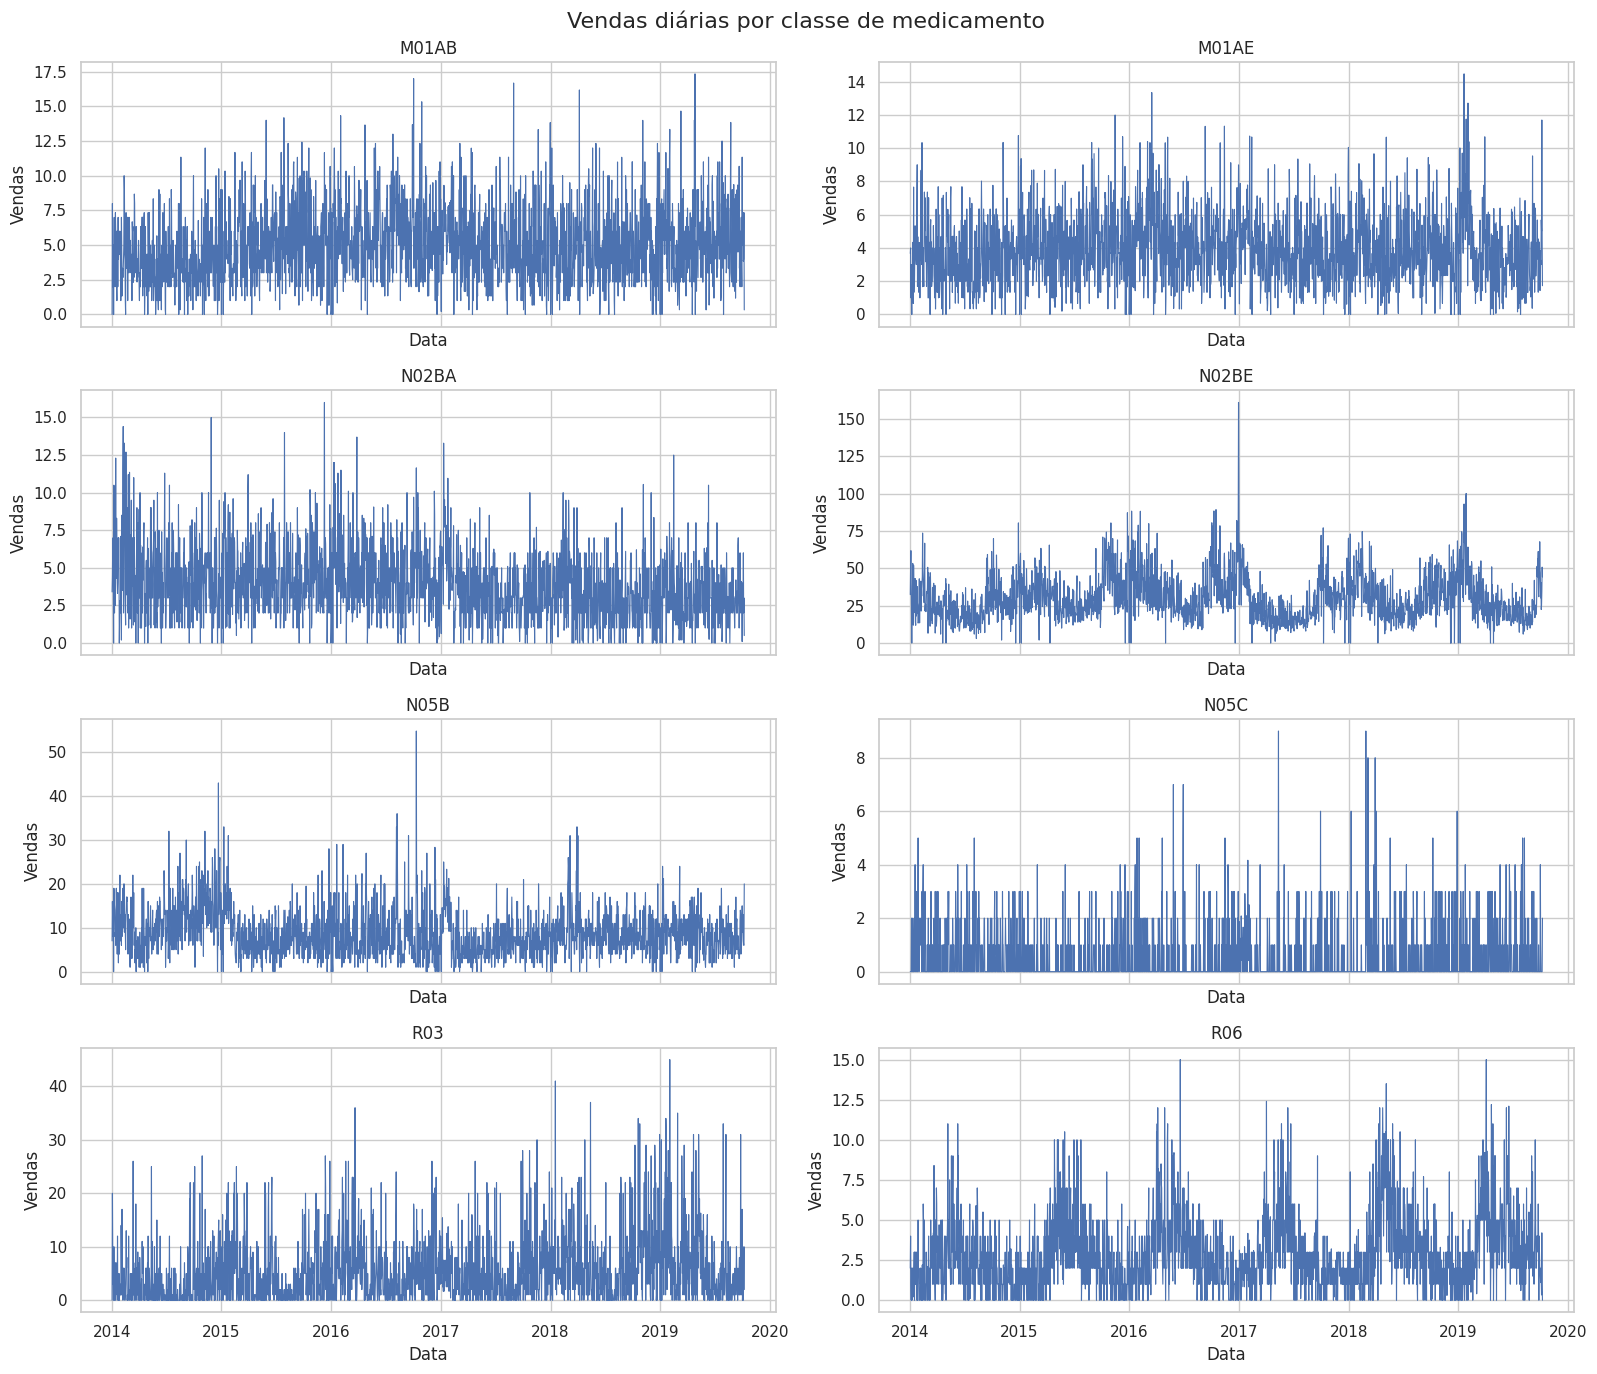

In [21]:
fig, axes = plt.subplots(4, 2, figsize=(16, 14), sharex=True)

for col, ax in zip(DRUG_COLS, axes.flatten()):
    ax.plot(df["datum"], df[col], linewidth=0.8)
    ax.set_title(col)
    ax.set_ylabel("Vendas")
    ax.set_xlabel("Data")

fig.suptitle("Vendas diárias por classe de medicamento", fontsize=16)
plt.tight_layout()
plt.show()



> Distribuição de vendas



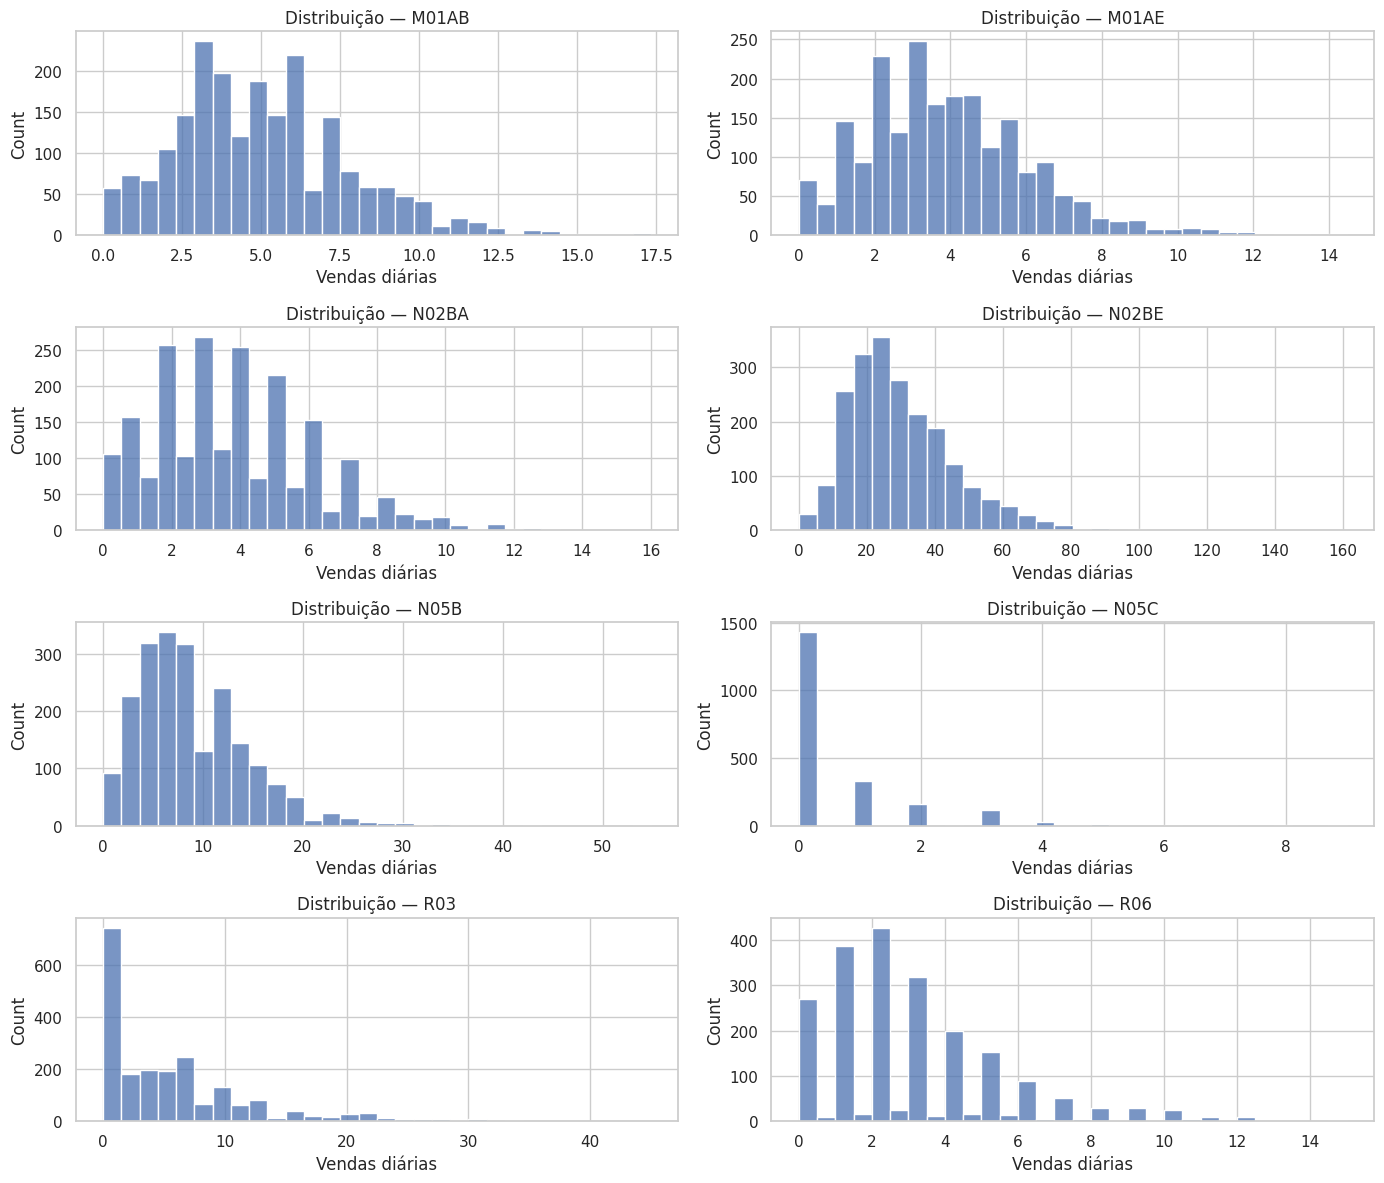

In [22]:
fig, axes = plt.subplots(4, 2, figsize=(14, 12))

for col, ax in zip(DRUG_COLS, axes.flatten()):
    sns.histplot(df[col].dropna(), bins=30, ax=ax)
    ax.set_title(f"Distribuição — {col}")
    ax.set_xlabel("Vendas diárias")

plt.tight_layout()
plt.show()



> Investigar o comportamento por dia da semana



,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
Weekday Name,,,,,,,,
Monday,5.06,3.72,3.89,29.23,9.25,0.62,5.95,2.90
Tuesday,5.05,3.55,4.23,28.37,9.62,0.73,5.41,3.05
Wednesday,4.80,3.70,3.77,28.07,10.12,0.65,5.45,2.67
Thursday,4.55,3.63,3.69,28.17,8.72,0.51,5.30,2.62
Friday,4.77,3.71,3.88,28.59,9.90,0.76,5.83,2.80
Saturday,5.73,4.36,4.19,33.58,8.57,0.55,5.41,3.28
Sunday,5.29,4.60,3.51,33.39,5.80,0.33,5.22,2.99


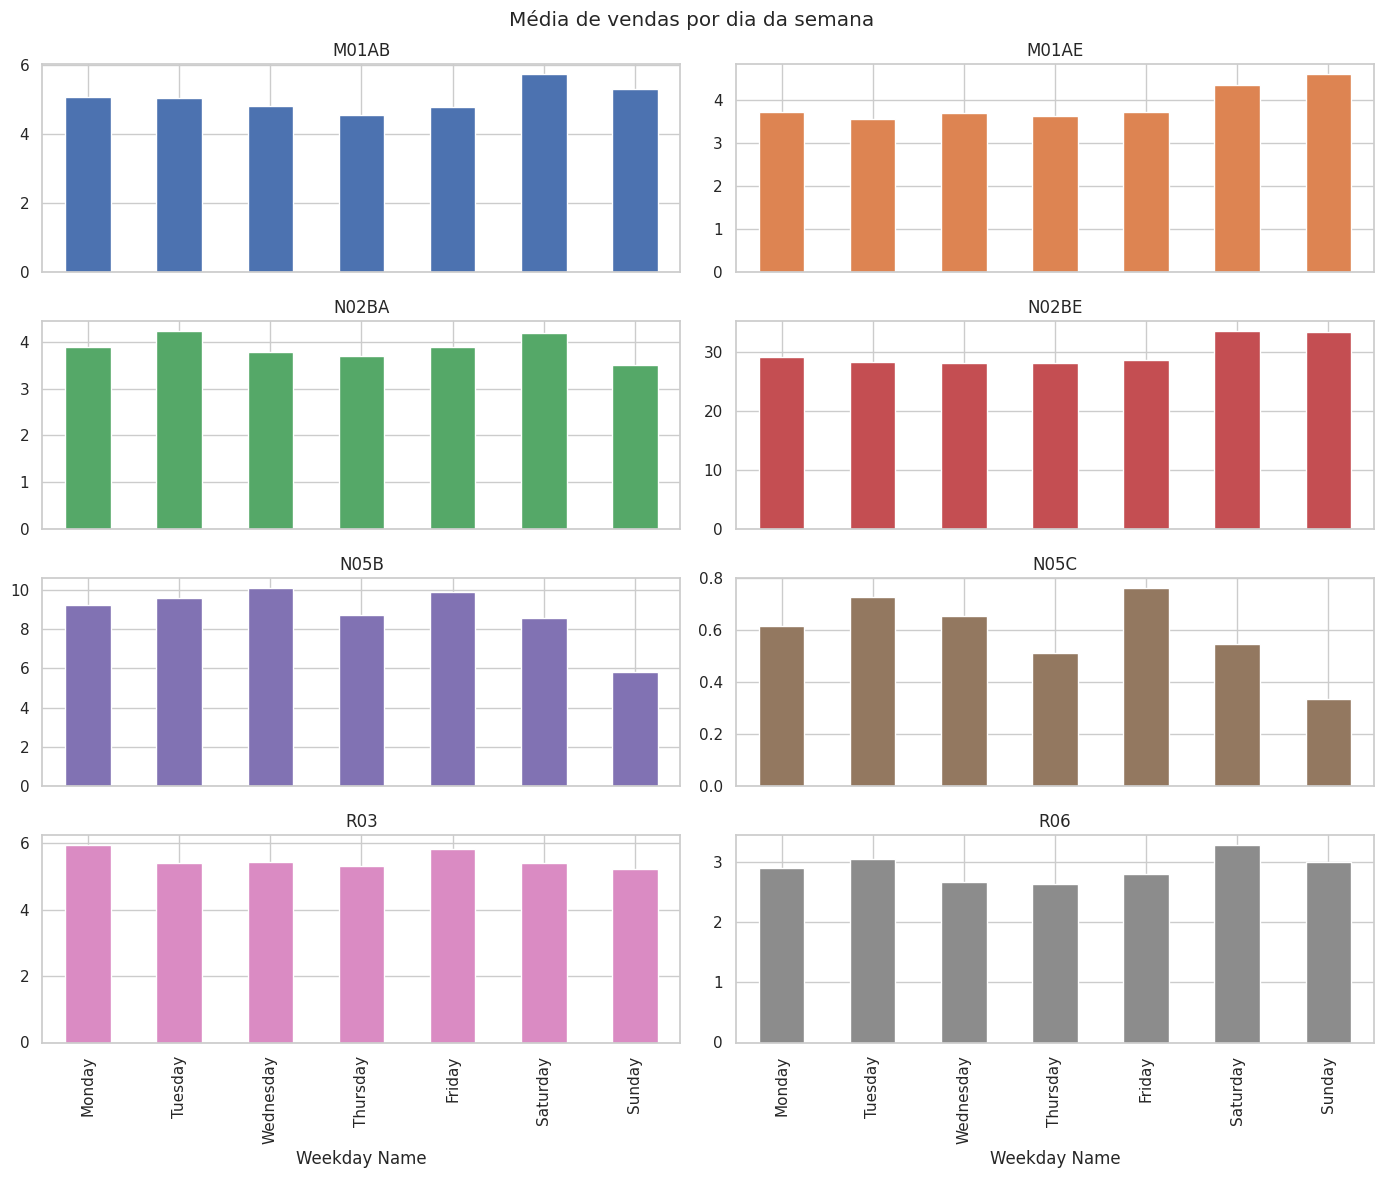

In [23]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_sales = (
    df.groupby("Weekday Name")[DRUG_COLS]
    .mean()
    .reindex(weekday_order)
)

display(weekday_sales)

weekday_sales.plot(
    kind="bar",
    subplots=True,
    layout=(4, 2),
    figsize=(14, 12),
    legend=False,
    sharex=True
)

plt.suptitle("Média de vendas por dia da semana")
plt.tight_layout()
plt.show()



> Investigar séries mensais



In [25]:

# Ordenar pela data e definir a data como índice
df_sorted = df.sort_values("datum").set_index("datum")

# Soma das vendas de cada classe em cada mês
monthly_sales = df_sorted[DRUG_COLS].resample("MS").sum(min_count=1)

# Quantidade de dias com registro em cada mês
monthly_observed_days = df_sorted.resample("MS").size()

# Quantidade de dias com vendas positivas por classe
monthly_positive_days = (
    df_sorted[DRUG_COLS]
    .gt(0)
    .resample("MS")
    .sum()
    .astype(int)
)

print("Dimensões da série mensal:", monthly_sales.shape)

display(monthly_sales.head())
display(monthly_observed_days.head())
display(monthly_positive_days.head())


Dimensões da série mensal: (70, 8)


,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
datum,,,,,,,,
2014-01-01,127.69,99.09,152.10,878.03,354.00,30.00,112.00,48.20
2014-02-01,133.32,126.05,177.00,"1,001.90",347.00,31.00,122.00,36.20
2014-03-01,137.44,92.95,147.66,779.27,232.00,20.00,112.00,85.40
2014-04-01,113.10,89.47,125.15,698.50,209.00,18.00,97.00,73.70
2014-05-01,101.79,119.93,132.10,628.78,270.00,23.00,107.00,123.70


,0
datum,
2014-01-01,30
2014-02-01,28
2014-03-01,31
2014-04-01,30
2014-05-01,31


,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
datum,,,,,,,,
2014-01-01,28,29,28,29,29,15,23,23
2014-02-01,27,28,28,28,28,18,21,17
2014-03-01,31,30,29,31,30,13,19,27
2014-04-01,29,29,29,29,29,12,19,28
2014-05-01,29,30,30,30,30,15,18,30




> Analisar evolução mensal



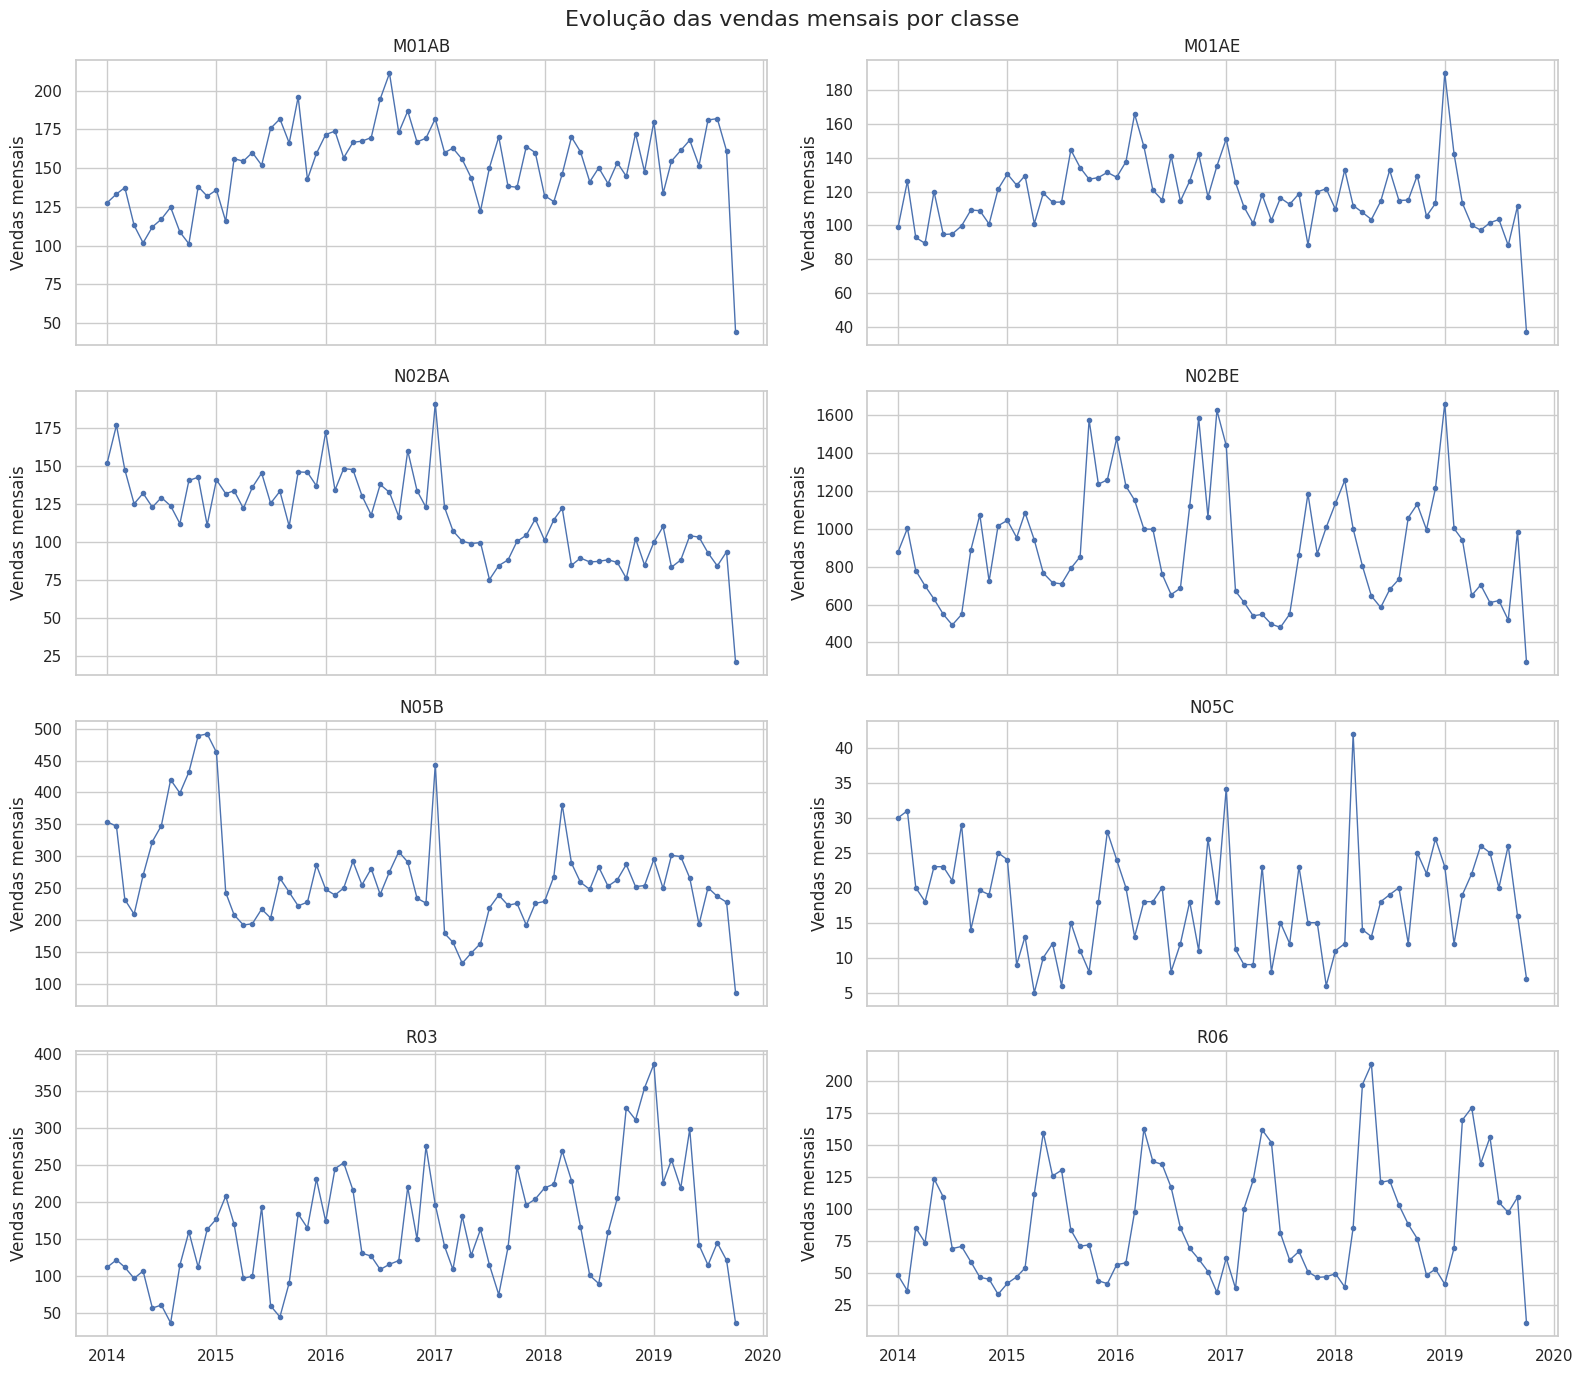

In [26]:
fig, axes = plt.subplots(4, 2, figsize=(16, 14), sharex=True)

for col, ax in zip(DRUG_COLS, axes.flatten()):
    ax.plot(monthly_sales.index, monthly_sales[col], marker=".", linewidth=1)
    ax.set_title(col)
    ax.set_ylabel("Vendas mensais")

fig.suptitle("Evolução das vendas mensais por classe", fontsize=16)
plt.tight_layout()
plt.show()



> Investigar sazonalidade mensal



,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
Jan,154.86,134.65,142.95,"1,272.15",338.82,24.36,210.78,49.88
Feb,140.82,131.27,131.79,"1,017.91",254.20,15.86,194.26,47.98
Mar,152.28,120.64,123.81,927.92,256.23,19.33,195.00,98.72
Apr,153.54,107.70,111.36,771.36,235.57,14.33,173.15,141.12
May,150.23,113.14,115.19,714.66,231.97,18.83,155.22,155.09
Jun,141.44,107.04,112.62,619.02,237.42,17.67,130.50,133.11
Jul,161.45,117.02,107.98,605.41,257.27,14.83,91.67,104.12
Aug,168.28,112.36,107.79,637.63,281.67,19.00,96.17,83.38
Sep,150.15,119.10,101.23,960.86,277.22,15.67,132.07,77.20
Oct,135.08,105.58,107.33,"1,139.99",257.32,14.27,195.83,53.10


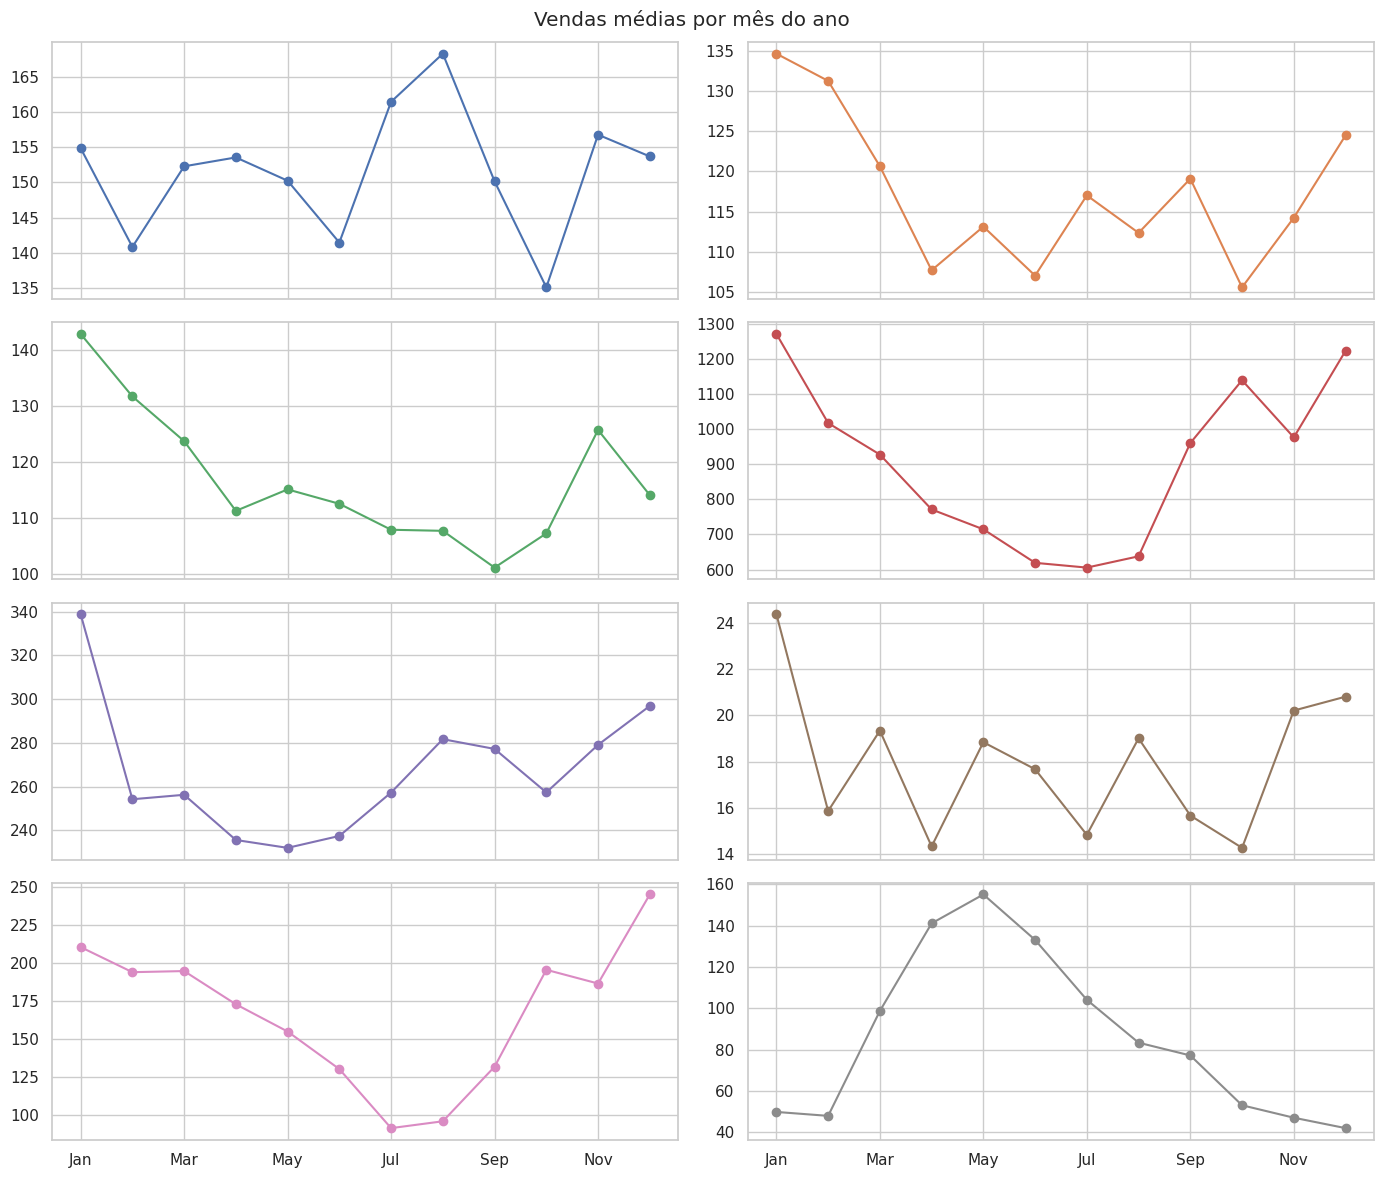

In [27]:
monthly_by_calendar_month = monthly_sales.groupby(
    monthly_sales.index.month
).mean()

monthly_by_calendar_month.index = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

display(monthly_by_calendar_month)

monthly_by_calendar_month.plot(
    subplots=True,
    layout=(4, 2),
    figsize=(14, 12),
    legend=False,
    marker="o"
)

plt.suptitle("Vendas médias por mês do ano")
plt.tight_layout()
plt.show()



> Comparação da frequência diária e mensal



In [28]:
frequency_summary = pd.DataFrame({
    "daily_mean": df[DRUG_COLS].mean(),
    "daily_std": df[DRUG_COLS].std(),
    "monthly_mean": monthly_sales.mean(),
    "monthly_std": monthly_sales.std()
})

display(frequency_summary)

,daily_mean,daily_std,monthly_mean,monthly_std
M01AB,5.03,2.74,151.44,26.43
M01AE,3.90,2.13,117.21,20.48
N02BA,3.88,2.38,116.75,27.99
N02BE,29.92,15.59,900.08,305.43
N05B,8.85,5.61,266.37,79.52
N05C,0.59,1.09,17.86,7.43
R03,5.51,6.43,165.84,75.70
R06,2.90,2.42,87.25,44.86


#### Correlação entre as classes de medicamentos



> Matriz de correlação



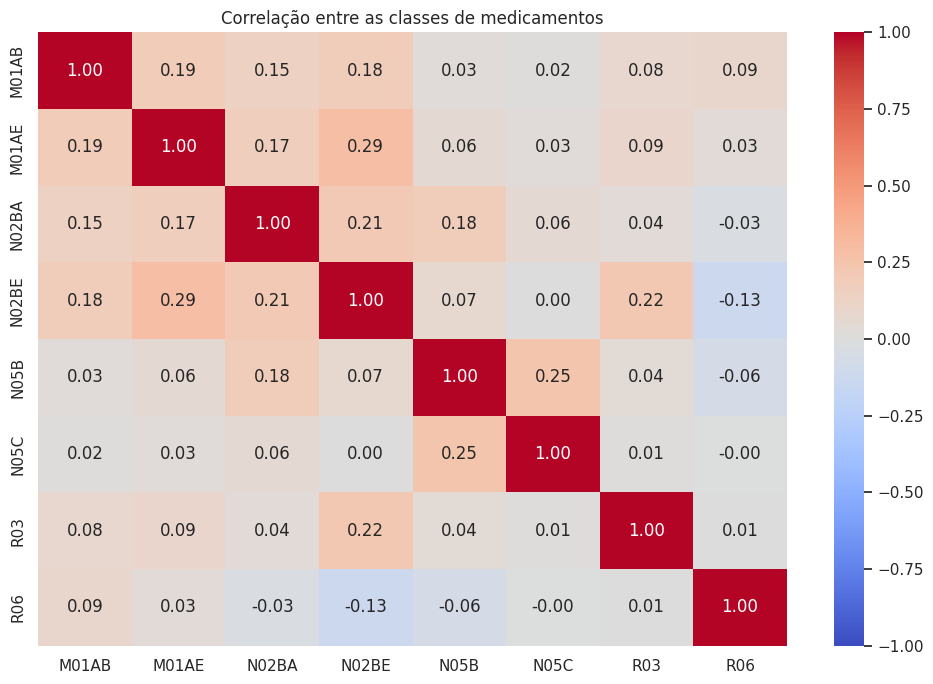

In [29]:
correlation = df[DRUG_COLS].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlação entre as classes de medicamentos")
plt.tight_layout()
plt.show()



> Correlação positiva significa que duas séries tendem a variar na mesma direção; correlação negativa indica tendências opostas. Isso não prova causalidade nem garante que usar as outras classes como variáveis explicativas melhore a previsão.


#### Inspeção das variáveis auxiliares (ex: horas)

In [30]:
for col in CALENDAR_COLS:
    print(f"\n--- {col} ---")
    print("Valores únicos:", df[col].nunique())
    print("Exemplos:", df[col].drop_duplicates().head(15).tolist())


--- Year ---
Valores únicos: 6
Exemplos: [2014, 2015, 2016, 2017, 2018, 2019]

--- Month ---
Valores únicos: 12
Exemplos: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

--- Hour ---
Valores únicos: 3
Exemplos: [248, 276, 190]

--- Weekday Name ---
Valores únicos: 7
Exemplos: ['Thursday', 'Friday', 'Saturday', 'Sunday', 'Monday', 'Tuesday', 'Wednesday']
